# 1. From Raw Swarm Trajectories to Five Invariant Kinematic Fields

**What you will learn:**
1. What a recorded ARGoS swarm trajectory looks like across all **five missions**.
2. How the **Gaussian footprint** $O_i(\mathbf{r}, t)$ turns discrete robots into continuous scalar/vector fields and acts as a spatial resolution lens (`2.35 * sigma` threshold, `5 * sigma` support).
3. Why all **three velocity moments** ($M_0, \mathbf{M}_1, M_2$) are needed — verified live on a synthetic crossing-streams experiment.
4. How the **closed-form Helmholtz–Hodge decomposition** splits net flux without a grid or Poisson solver via the radial kernel $\kappa_\sigma(\mathbf{d})$.
5. Why the **Jacobi coupling** $J_\sigma = \sigma^2 \det(\nabla\varphi_\sigma, \nabla\psi_\sigma)$ detects whether sources/sinks coincide with rotation centers.
6. Numerical verification on real e-puck exemplars and exact **$\mathrm{SO}(2)$ rotation equivariance**.

In [1]:
import pickle, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import make_figures as M
L.style()

PAPER = ROOT / "results" / "epuck" / "paper"
RES = ROOT / "results" / "epuck"
load = lambda p: pickle.load(open(p, "rb"))

## 1. Exploring Real Swarm Recordings (`Top-1`, 250 runs)

Each recording tracks $N = 20$ e-puck robots inside a $4.91\,\mathrm{m}^2$ dodecagonal arena over $T = 1199$ steps ($\Delta t = 0.1\,\mathrm{s}$ for `120 s`, subsampled/truncated in the Top-1 cache). Forward differences $\mathbf{v}_i(t) = (\mathbf{x}_i(t+\Delta t) - \mathbf{x}_i(t))/\Delta t$ give every robot's velocity. Notice how **positions + velocities alone** already separate motion styles before any sensor data!

Loaded 250 runs  |  pos shape per run: (1199, 20, 2)  |  vel shape: (1199, 20, 2)
Modal exemplars index by mission: {'D-Gate': 24, 'Foraging': 80, 'Homing': 145, 'Shelter': 170, 'XOR': 244}


/home/ndinga/Documents/paper_topological_kinematics/.venv_torch/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 118 (v) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


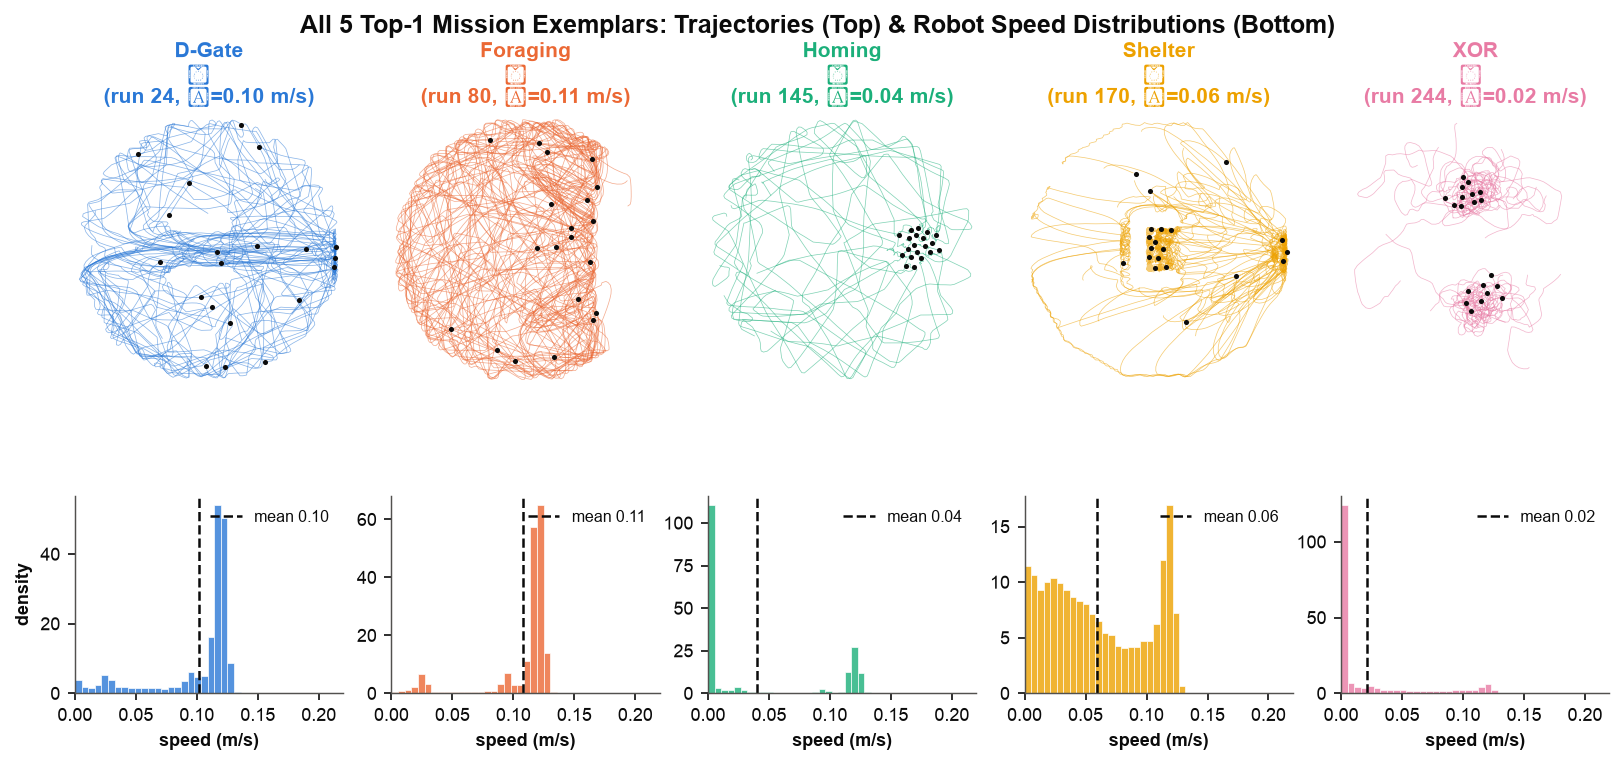

In [2]:
d = load(PAPER / "top1_tracks.pkl")
tax = load(PAPER / "taxonomy.pkl")[1]
tracks, lab = d["tracks"], d["labels"]

# Order the discovered modal exemplars by mission index 0..4
ex_by_m = {int(lab[e]): int(e) for e in tax["exemplars"]}
print(f"Loaded {len(tracks)} runs  |  pos shape per run: {tracks[0]['pos'].shape}  |  vel shape: {tracks[0]['vel'].shape}")
print("Modal exemplars index by mission:", {L.MSHORT[m]: ex_by_m[m] for m in range(5)})

fig = plt.figure(figsize=(13.2, 5.2))
gs = fig.add_gridspec(2, 5, height_ratios=[1.35, 0.85], hspace=0.35, wspace=0.18)

for m in range(5):
    e = ex_by_m[m]
    pos = tracks[e]["pos"]
    vel = tracks[e]["vel"]
    speeds = np.linalg.norm(vel, axis=-1).ravel()

    ax = fig.add_subplot(gs[0, m])
    M.draw_tracks(ax, pos, L.MCOL[m], every=4)
    ax.set_title(f"{L.MSHORT[m]}\n(run {e}, v̄={speeds.mean():.2f} m/s)", color=L.MCOL[m], fontsize=10, fontweight="bold")

    ax_h = fig.add_subplot(gs[1, m])
    ax_h.hist(speeds, bins=25, density=True, color=L.MCOL[m], alpha=0.80, edgecolor="white", lw=0.4)
    ax_h.axvline(speeds.mean(), color=L.INK, ls="--", lw=1.2, label=f"mean {speeds.mean():.2f}")
    ax_h.set_xlim(0, 0.22)
    ax_h.set_xlabel("speed (m/s)", fontsize=8.5)
    if m == 0:
        ax_h.set_ylabel("density", fontsize=8.5)
    ax_h.legend(fontsize=7.5, frameon=False, loc="upper right")

fig.suptitle("All 5 Top-1 Mission Exemplars: Trajectories (Top) & Robot Speed Distributions (Bottom)", fontsize=12, fontweight="bold", y=0.98)
plt.show()

**Takeaway:** Notice the contrast in speed profiles! **D-Gate** and **Foraging** stay continuously mobile near full speed ($\sim 0.12\text{ m/s}$), whereas **Shelter** and **XOR** have a large peak near $0\text{ m/s}$ because robots settle on their target patches, and **Homing** mixes crossing + resting!

## 2. The Gaussian Footprint $O_i$ & the $2.35\,\sigma$ Resolution Lens

Each robot at $\mathbf{x}_i(t)$ radiates an isotropic bump of scale $\sigma$:
$$O_i(\mathbf{r}, t) = \exp\!\left(-\frac{\|\mathbf{r} - \mathbf{x}_i(t)\|^2}{2\sigma^2}\right)$$

Why Gaussian? It is smooth, isotropic ($\mathrm{SO}(2)$-invariant), negligible outside a $5\sigma$ ball ($e^{-12.5} \approx 3.7\times 10^{-6}$ of its peak), and yields **exact closed-form Helmholtz–Hodge potentials**. Two footprints spaced $d$ apart blend into a single bump below the FWHM scale $d \le 2\sqrt{2\ln 2}\,\sigma \approx 2.35\,\sigma$, so $\sigma$ smoothly tunes our lens from individual robots to group-level clusters.

Fraction omitted outside 5*sigma boundary: exp(-12.5) = 3.727e-06


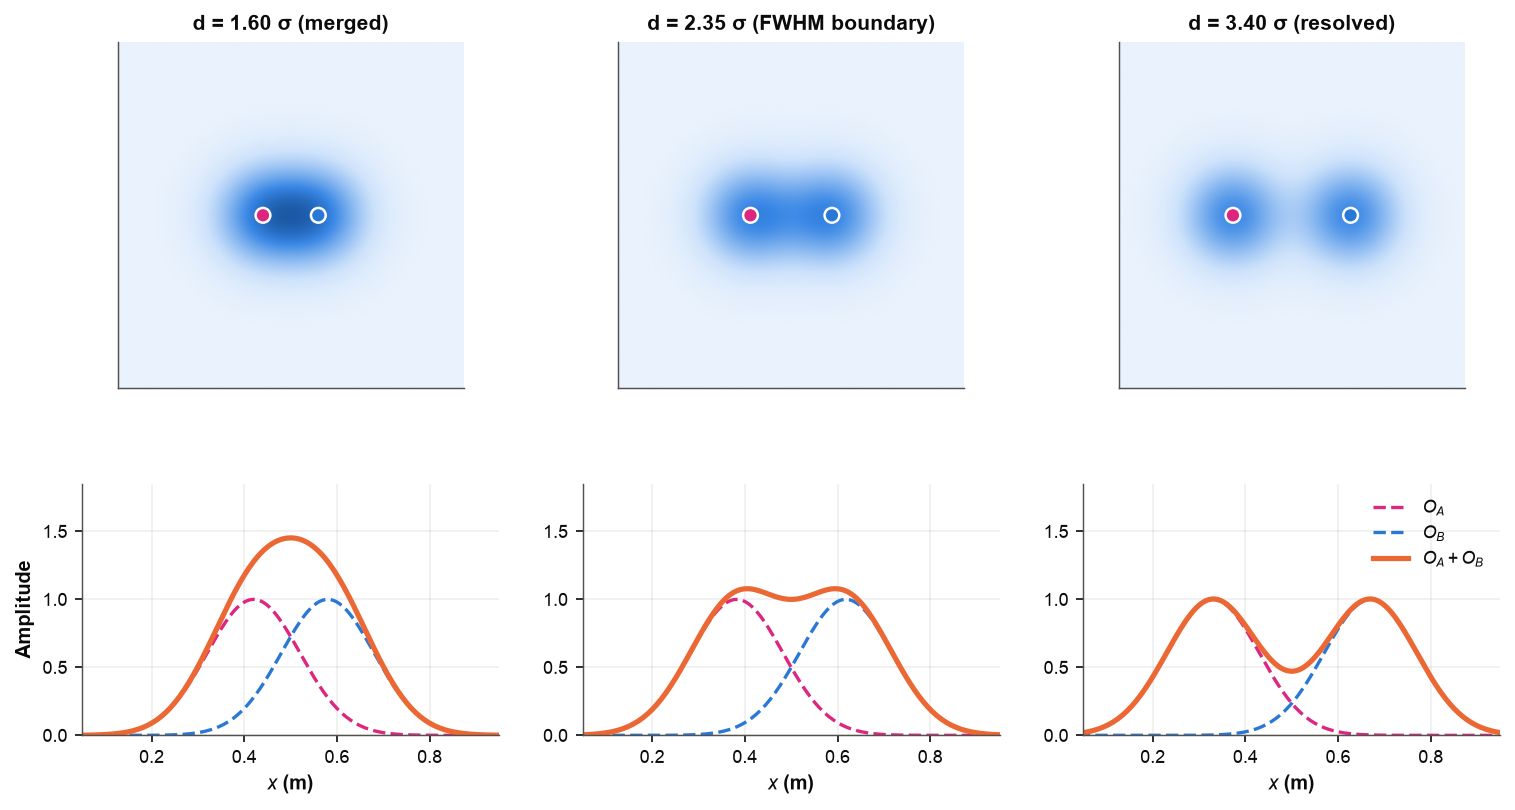

In [3]:
sigma = 0.10  # 10 cm lens for demonstration
xs = np.linspace(0, 1.0, 201)
xg, yg = np.meshgrid(xs, xs)
seps = [1.6 * sigma, 2.3548 * sigma, 3.4 * sigma]
labels_sep = [f"d = 1.60 σ (merged)", f"d = 2.35 σ (FWHM boundary)", f"d = 3.40 σ (resolved)"]

fig, axes = plt.subplots(2, 3, figsize=(12.2, 6.0), gridspec_kw={"height_ratios": [1.1, 0.8], "hspace": 0.32, "wspace": 0.20})
mid = len(xs) // 2

for j, (d_ab, tit) in enumerate(zip(seps, labels_sep)):
    xA, xB = 0.5 - d_ab / 2, 0.5 + d_ab / 2
    oA = np.exp(-((xg - xA)**2 + (yg - 0.5)**2) / (2 * sigma**2))
    oB = np.exp(-((xg - xB)**2 + (yg - 0.5)**2) / (2 * sigma**2))
    m0 = oA + oB

    axes[0, j].imshow(m0, origin="lower", extent=[0, 1, 0, 1], cmap=L.SEQ, vmin=0, vmax=1.8)
    axes[0, j].scatter([xA, xB], [0.5, 0.5], c=["#DC267F", "#2a78d6"], s=50, ec="white", lw=1.2, zorder=5)
    axes[0, j].set_title(tit, fontsize=10, fontweight="bold")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])

    axes[1, j].plot(xs, oA[mid], color="#DC267F", lw=1.6, ls="--", label="$O_A$")
    axes[1, j].plot(xs, oB[mid], color="#2a78d6", lw=1.6, ls="--", label="$O_B$")
    axes[1, j].plot(xs, m0[mid], color="#eb6834", lw=2.5, label="$O_A + O_B$")
    axes[1, j].set_ylim(0, 1.85); axes[1, j].set_xlim(0.05, 0.95)
    axes[1, j].set_xlabel("$x$ (m)"); axes[1, j].grid(alpha=0.2)
    if j == 0:
        axes[1, j].set_ylabel("Amplitude")
    if j == 2:
        axes[1, j].legend(fontsize=8.5, frameon=False)

print(f"Fraction omitted outside 5*sigma boundary: exp(-12.5) = {np.exp(-12.5):.3e}")
plt.show()

## 3. Why All Three Velocity Moments ($M_0, \mathbf{M}_1, M_2$) Are Needed

Weighting position and velocity moments by $O_i(\mathbf{r}, t)$ gives:
$$M_0(\mathbf{r},t)=\sum_i O_i,\qquad \mathbf{M}_1(\mathbf{r},t)=\sum_i \mathbf{v}_i O_i,\qquad \operatorname{tr}M_2(\mathbf{r},t)=\sum_i \|\mathbf{v}_i\|^2 O_i.$$

Let's construct a **toy swarm** with three distinct zones at one instant:
1. Top-left: a **resting cluster** ($\mathbf{v}_i = 0$) — visible in $M_0$, invisible in $\mathbf{M}_1, M_2$.
2. Center: **two crossing streams** ($+v_x$ and $-v_x$) — their velocities **cancel in net flux $\mathbf{M}_1$** yet **add in agitation $\operatorname{tr}M_2$ ($K_\sigma$)**!
3. Bottom-right: a **coherent stream** — visible in all three moments!

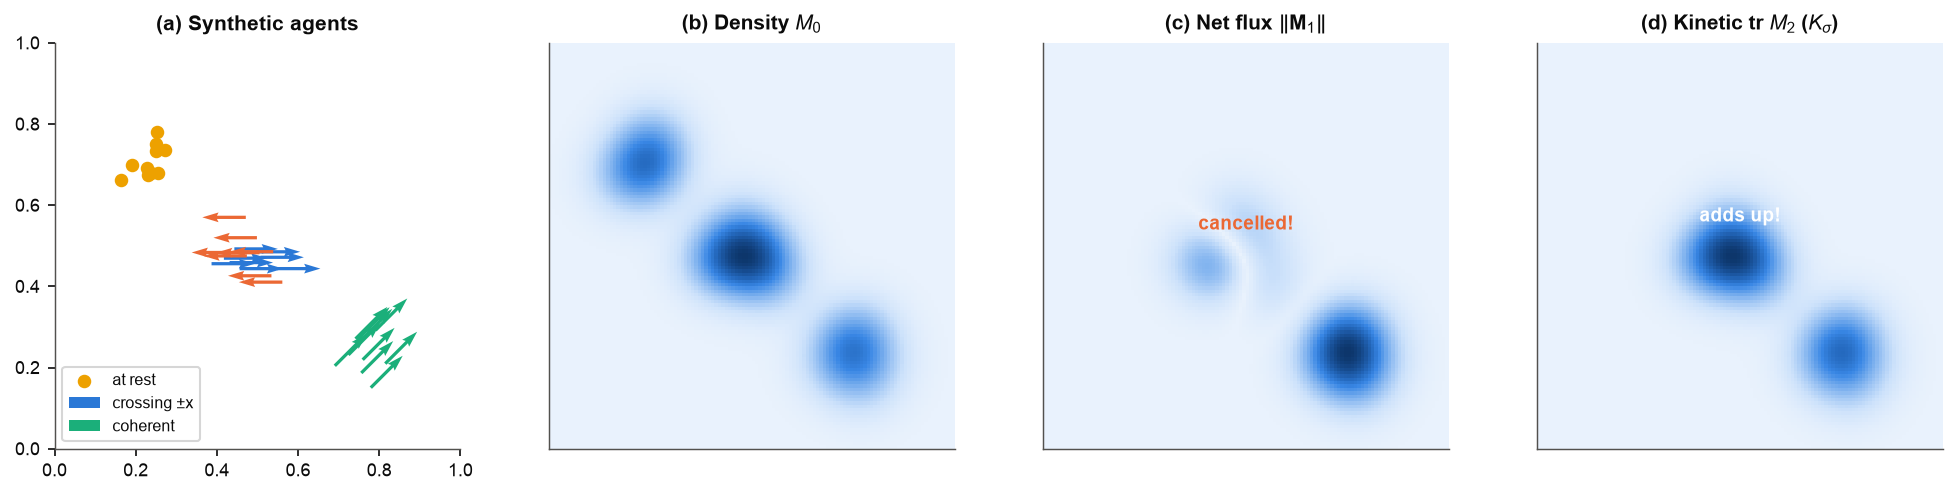

In [4]:
rng = np.random.default_rng(7)
pos_rest = rng.normal([0.25, 0.72], 0.045, (10, 2));   vel_rest = np.zeros_like(pos_rest)
pos_c1   = rng.normal([0.50, 0.48], 0.045, (8, 2));    vel_c1   = np.tile([+0.15, 0.0], (8, 1))
pos_c2   = rng.normal([0.50, 0.48], 0.045, (8, 2));    vel_c2   = np.tile([-0.15, 0.0], (8, 1))
pos_move = rng.normal([0.75, 0.24], 0.045, (10, 2));   vel_move = np.tile([0.11, 0.11], (10, 1))

P_toy = np.vstack([pos_rest, pos_c1, pos_c2, pos_move])[None, :, :]
V_toy = np.vstack([vel_rest, vel_c1, vel_c2, vel_move])[None, :, :]

xs_t = np.linspace(0, 1, 120)
Xg, Yg = np.meshgrid(xs_t, xs_t)
dx = Xg[..., None] - P_toy[0, :, 0]
dy = Yg[..., None] - P_toy[0, :, 1]
sig_t = 0.065
O = np.exp(-(dx**2 + dy**2) / (2 * sig_t**2))
M0 = O.sum(-1)
M1x = (O * V_toy[0, :, 0]).sum(-1)
M1y = (O * V_toy[0, :, 1]).sum(-1)
M1mag = np.hypot(M1x, M1y)
M2tr = (O * (V_toy[0, :, 0]**2 + V_toy[0, :, 1]**2)).sum(-1)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.2))
axes[0].scatter(pos_rest[:,0], pos_rest[:,1], c=L.MCOL[3], s=30, label="at rest")
axes[0].quiver(pos_c1[:,0], pos_c1[:,1], vel_c1[:,0], vel_c1[:,1], color=L.MCOL[0], scale=1.4, width=0.008, label="crossing ±x")
axes[0].quiver(pos_c2[:,0], pos_c2[:,1], vel_c2[:,0], vel_c2[:,1], color=L.MCOL[1], scale=1.4, width=0.008)
axes[0].quiver(pos_move[:,0], pos_move[:,1], vel_move[:,0], vel_move[:,1], color=L.MCOL[2], scale=1.4, width=0.008, label="coherent")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1); axes[0].set_aspect("equal"); axes[0].legend(fontsize=7.5, loc="lower left")
axes[0].set_title("(a) Synthetic agents")

for ax, field, tit in zip(axes[1:], [M0, M1mag, M2tr], ["(b) Density $M_0$", "(c) Net flux $\\|\\mathbf{M}_1\\|$", "(d) Kinetic tr $M_2$ ($K_\\sigma$)"]):
    ax.imshow(field, origin="lower", extent=[0, 1, 0, 1], cmap=L.SEQ)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(tit, fontsize=10, fontweight="bold")
axes[2].text(0.50, 0.54, "cancelled!", color=L.MCOL[1], fontweight="bold", ha="center", fontsize=9)
axes[3].text(0.50, 0.56, "adds up!", color="white", fontweight="bold", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Exact Closed-Form Helmholtz–Hodge Potentials ($\varphi_\sigma, \psi_\sigma$)

Because the time-averaged flux $\bar{\mathbf{V}}_\sigma(\mathbf{r})$ is a sum of Gaussians over the unbounded plane, it has **no boundary condition ambiguities and zero harmonic part**. Its divergence potential $\varphi_\sigma$ (sinks/sources) and vorticity potential $\psi_\sigma$ (rotation centers) follow in exact closed form via one bounded radial kernel:
$$\kappa_\sigma(\mathbf{d}) = \frac{\sigma^2}{\|\mathbf{d}\|^2}\left(1 - e^{-\|\mathbf{d}\|^2/(2\sigma^2)}\right), \qquad \kappa_\sigma(\mathbf{0}) = \frac{1}{2}.$$

Let's plot $\kappa_\sigma(r)$ alongside its $1/r^2$ tail, then build synthetic **sink**, **source**, and **vortex** swarms and verify numerically that $\nabla \varphi_\sigma + \nabla^\perp \psi_\sigma$ reconstructs $\bar{\mathbf{V}}_\sigma$!

Finite-diff check over 81% valid interior: || (∇φ + ∇⊥ψ) - V̄ || / ||V̄|| = 3.70e-03 (O(Δx^2))


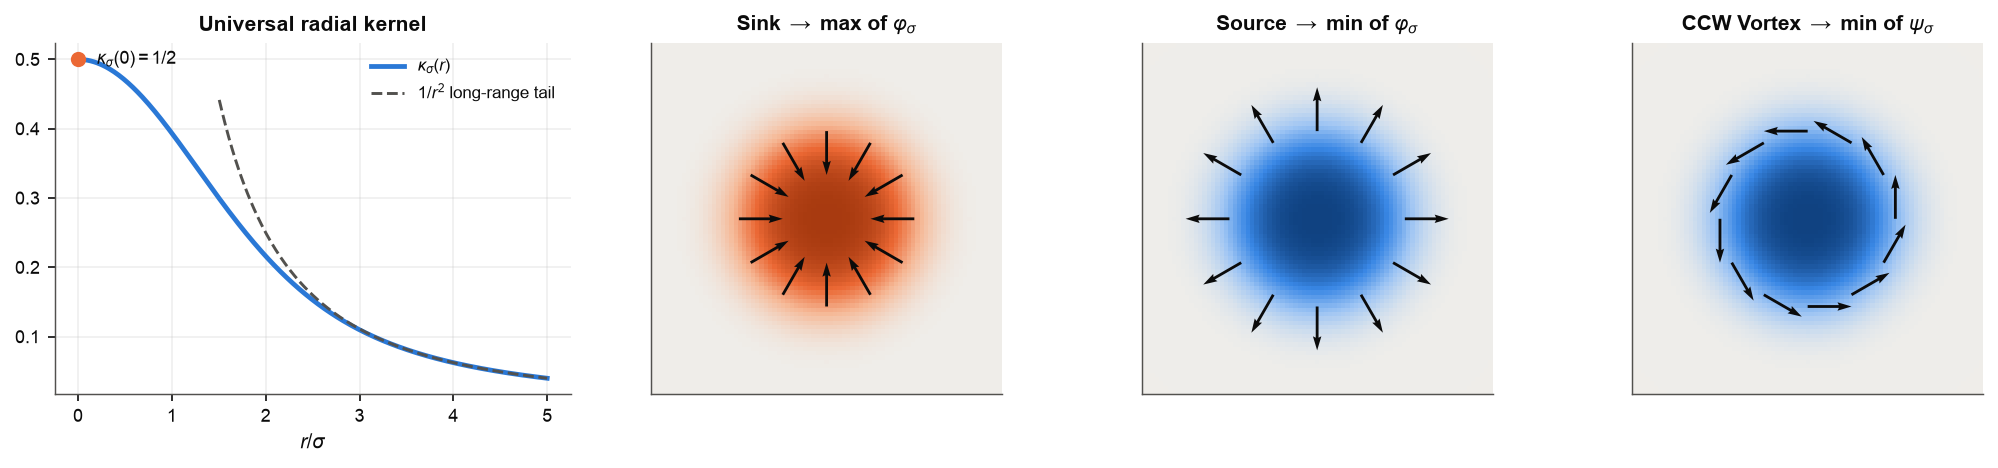

In [5]:
from gaussian_splatting.fields_cpu import FieldComputer
from types import SimpleNamespace

fig, axes = plt.subplots(1, 4, figsize=(13.8, 3.2), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]})

# Panel 0: Radial kernel kappa_sigma
r = np.linspace(0, 5.0, 300)
kap = np.where(r > 1e-8, (1.0 - np.exp(-r**2 / 2.0)) / np.maximum(r**2, 1e-12), 0.5)
tail = 1.0 / np.maximum(r, 1.5)**2
axes[0].plot(r, kap, color=L.MCOL[0], lw=2.3, label=r"$\kappa_\sigma(r)$")
axes[0].plot(r[r >= 1.5], tail[r >= 1.5], color=L.INK2, ls="--", lw=1.4, label=r"$1/r^2$ long-range tail")
axes[0].scatter([0], [0.5], color=L.MCOL[1], s=40, zorder=5); axes[0].text(0.2, 0.50, r"$\kappa_\sigma(0)=1/2$", va="center", fontsize=8.5)
axes[0].set_xlabel(r"$r / \sigma$"); axes[0].set_title("Universal radial kernel", fontsize=10, fontweight="bold")
axes[0].legend(fontsize=8, frameon=False); axes[0].grid(alpha=0.2)

# Panels 1-3: Sink, Source, CCW Vortex computed via actual FieldComputer
th = np.linspace(0, 2 * np.pi, 24, endpoint=False)
rad = 0.25
c = np.array([L.ARENA / 2, L.ARENA / 2])
px = c[0] + rad * np.cos(th); py = c[1] + rad * np.sin(th)
ux, uy = np.cos(th), np.sin(th)
sig_h = 0.08
xs_h = np.linspace(c[0] - 0.5, c[0] + 0.5, 81)
Xh, Yh = np.meshgrid(xs_h, xs_h)
grid_h = SimpleNamespace(X=Xh, Y=Yh, shape=Xh.shape, sigma=sig_h, n_vertices=Xh.size)
fc = FieldComputer(fields=("phi", "psi"), kappa=5.0)

demos = [
    (r"Sink $\to$ max of $\varphi_\sigma$", np.c_[px, py], np.c_[-ux, -uy], "phi"),
    (r"Source $\to$ min of $\varphi_\sigma$", np.c_[px, py], np.c_[+ux, +uy], "phi"),
    (r"CCW Vortex $\to$ min of $\psi_\sigma$", np.c_[px, py], np.c_[-uy, +ux], "psi"),
]
for ax, (tit, pp, vv, fkey) in zip(axes[1:], demos):
    out = fc.compute(pp[None, ...], vv[None, ...], grid_h)
    Z = np.nan_to_num(out[fkey], 0.0)
    lim = np.max(np.abs(Z)) or 1.0
    ax.imshow(Z, origin="lower", extent=[xs_h[0], xs_h[-1], xs_h[0], xs_h[-1]], cmap=L.DIV, vmin=-lim, vmax=lim)
    ax.quiver(pp[::2,0], pp[::2,1], vv[::2,0], vv[::2,1], color=L.INK, scale=8, width=0.008)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(tit, fontsize=10, fontweight="bold")

# Verify grad(phi) + grad^perp(psi) = V_bar analytically on Sink+Vortex mix
pos_mix = np.vstack([np.c_[px, py] - 0.15, np.c_[px, py] + 0.15])[None, ...]
vel_mix = np.vstack([np.c_[-ux, -uy], np.c_[-uy, +ux]])[None, ...]
out_m = fc.compute(pos_mix, vel_mix, grid_h)
dx_h = xs_h[1] - xs_h[0]
dphi_dy, dphi_dx = np.gradient(out_m["phi"], dx_h, dx_h)
dpsi_dy, dpsi_dx = np.gradient(out_m["psi"], dx_h, dx_h)
Vx_rec, Vy_rec = dphi_dx - dpsi_dy, dphi_dy + dpsi_dx
# Direct gaussian flux average
dx_p = Xh[..., None] - pos_mix[0, :, 0]; dy_p = Yh[..., None] - pos_mix[0, :, 1]
W_p = np.exp(-(dx_p**2 + dy_p**2) / (2 * sig_h**2))
vbar = np.linalg.norm(vel_mix[0], axis=-1).mean()
Vx_dir = (W_p * vel_mix[0, :, 0]).sum(-1) / (pos_mix.shape[1] * sig_h * vbar)
Vy_dir = (W_p * vel_mix[0, :, 1]).sum(-1) / (pos_mix.shape[1] * sig_h * vbar)
finite = np.isfinite(Vx_rec) & np.isfinite(Vy_rec)
finite[:4, :] = finite[-4:, :] = finite[:, :4] = finite[:, -4:] = False
err = np.hypot(Vx_rec[finite] - Vx_dir[finite], Vy_rec[finite] - Vy_dir[finite]).max() / np.hypot(Vx_dir[finite], Vy_dir[finite]).max()
print(f"Finite-diff check over {100*finite.mean():.0f}% valid interior: || (∇φ + ∇⊥ψ) - V̄ || / ||V̄|| = {err:.2e} (O(Δx^2))")
plt.tight_layout(); plt.show()

## 5. Jacobi Coupling $J_\sigma$: Coinciding vs Displaced Sink & Vortex

Taken separately, the persistence diagrams of $\varphi_\sigma$ and $\psi_\sigma$ don't reveal *where* convergence and rotation sit relative to one another. $J_\sigma = \sigma^2 \det(\nabla\varphi_\sigma, \nabla\psi_\sigma)$ acts as a local joint detector: it vanishes where gradients align or overlap symmetrically, and lights up when a sink and vortex lie side by side (`fig_potentials`).

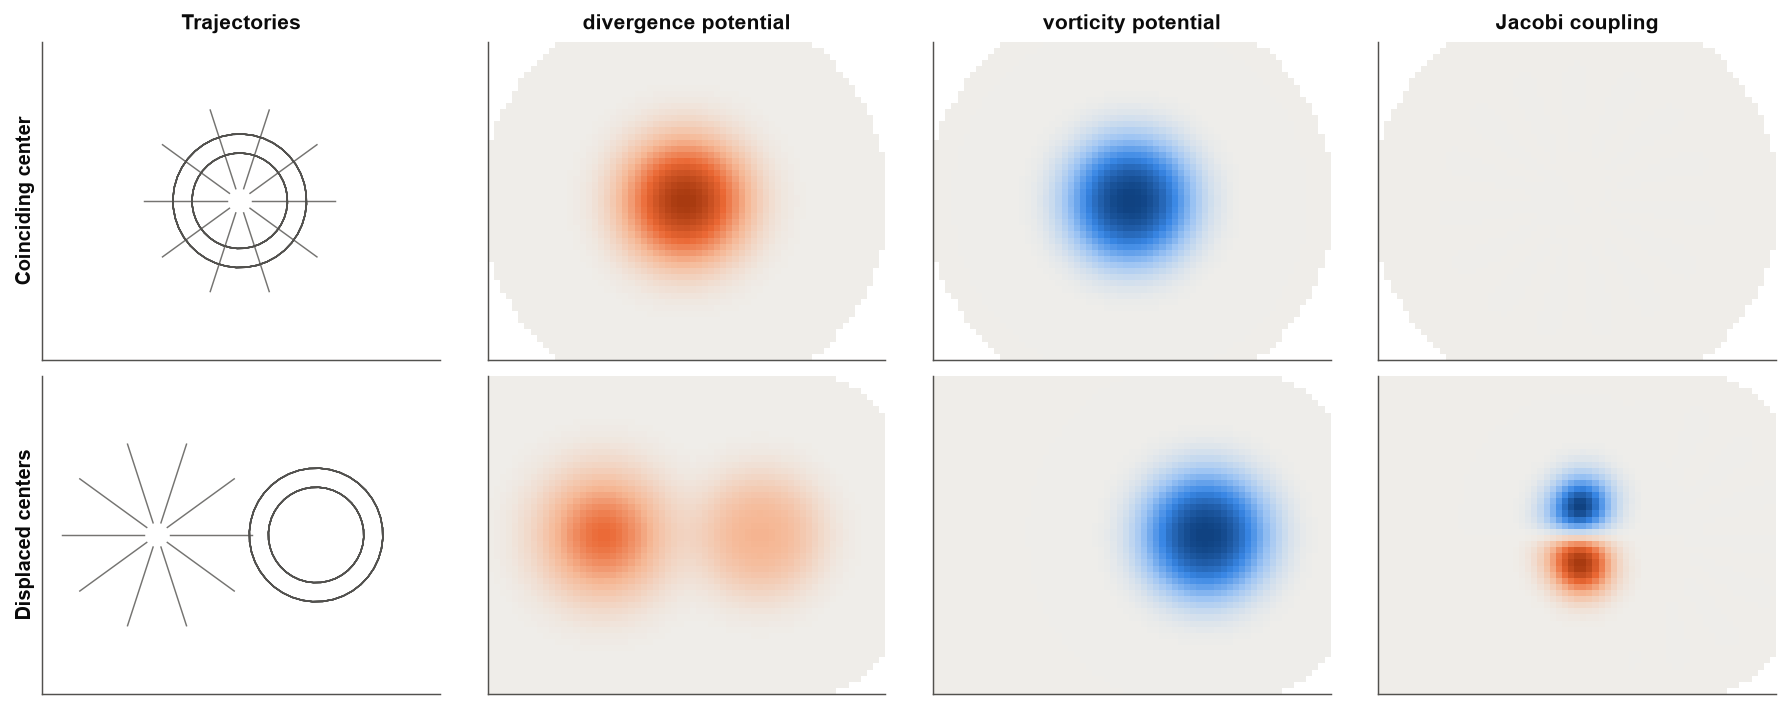

Peak |J_sigma|: coinciding = 0.0000  |  displaced = 0.0003


In [6]:
import illustrations as I
pair = I.coupling_pair(n=30, T=60)
fc_c = FieldComputer(fields=("phi", "psi", "J"), kappa=5.0, chunk_size=60)
xs_c = np.linspace(0, 1.25, 65); ys_c = np.linspace(0, 1.0, 52)
Xc, Yc = np.meshgrid(xs_c, ys_c)
gc = SimpleNamespace(X=Xc, Y=Yc, shape=Xc.shape, sigma=0.07, n_vertices=Xc.size)

Fc = {}
for name, P in pair.items():
    Fc[name] = fc_c.compute(P[:-1].astype(np.float32), ((P[1:] - P[:-1]) / 0.1).astype(np.float32), gc)

lim = {k: max(np.nanmax(np.abs(Fc["together"][k])), np.nanmax(np.abs(Fc["apart"][k]))) for k in ("phi", "psi", "J")}
fig, axes = plt.subplots(2, 4, figsize=(12.2, 4.8))
for r_i, (row_lbl, key_p) in enumerate([("Coinciding center", "together"), ("Displaced centers", "apart")]):
    P = pair[key_p]
    axes[r_i, 0].plot(P[:, ::3, 0], P[:, ::3, 1], color=L.INK2, lw=0.7, alpha=0.8)
    axes[r_i, 0].set_xlim(0, 1.25); axes[r_i, 0].set_ylim(0, 1.0); axes[r_i, 0].set_aspect("equal")
    axes[r_i, 0].set_ylabel(row_lbl, fontsize=9.5, fontweight="bold"); axes[r_i, 0].set_xticks([]); axes[r_i, 0].set_yticks([])
    for c_i, fkey in enumerate(("phi", "psi", "J")):
        axes[r_i, c_i + 1].imshow(np.ma.masked_invalid(Fc[key_p][fkey]), origin="lower", extent=(0, 1.25, 0, 1.0), cmap=L.FCMAP[fkey], vmin=-lim[fkey], vmax=lim[fkey])
        axes[r_i, c_i + 1].set_xticks([]); axes[r_i, c_i + 1].set_yticks([])
        if r_i == 0:
            axes[0, c_i + 1].set_title(L.FNAME[fkey], fontsize=10, fontweight="bold")
axes[0, 0].set_title("Trajectories", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Peak |J_sigma|: coinciding = {np.nanmax(np.abs(Fc['together']['J'])):.4f}  |  displaced = {np.nanmax(np.abs(Fc['apart']['J'])):.4f}")

## 6. All Five Fields on Real e-puck Exemplars + Exact $\mathrm{SO}(2)$ Rotation Check

Let's inspect the cached closed-form fields at scale $\sigma_3 = 7.18\text{ cm}$ across all five Top-1 mission exemplars, then **recompute the fields from scratch** on the Shelter exemplar and on its $+90^\circ$ rotated copy to verify exact rotation equivariance!

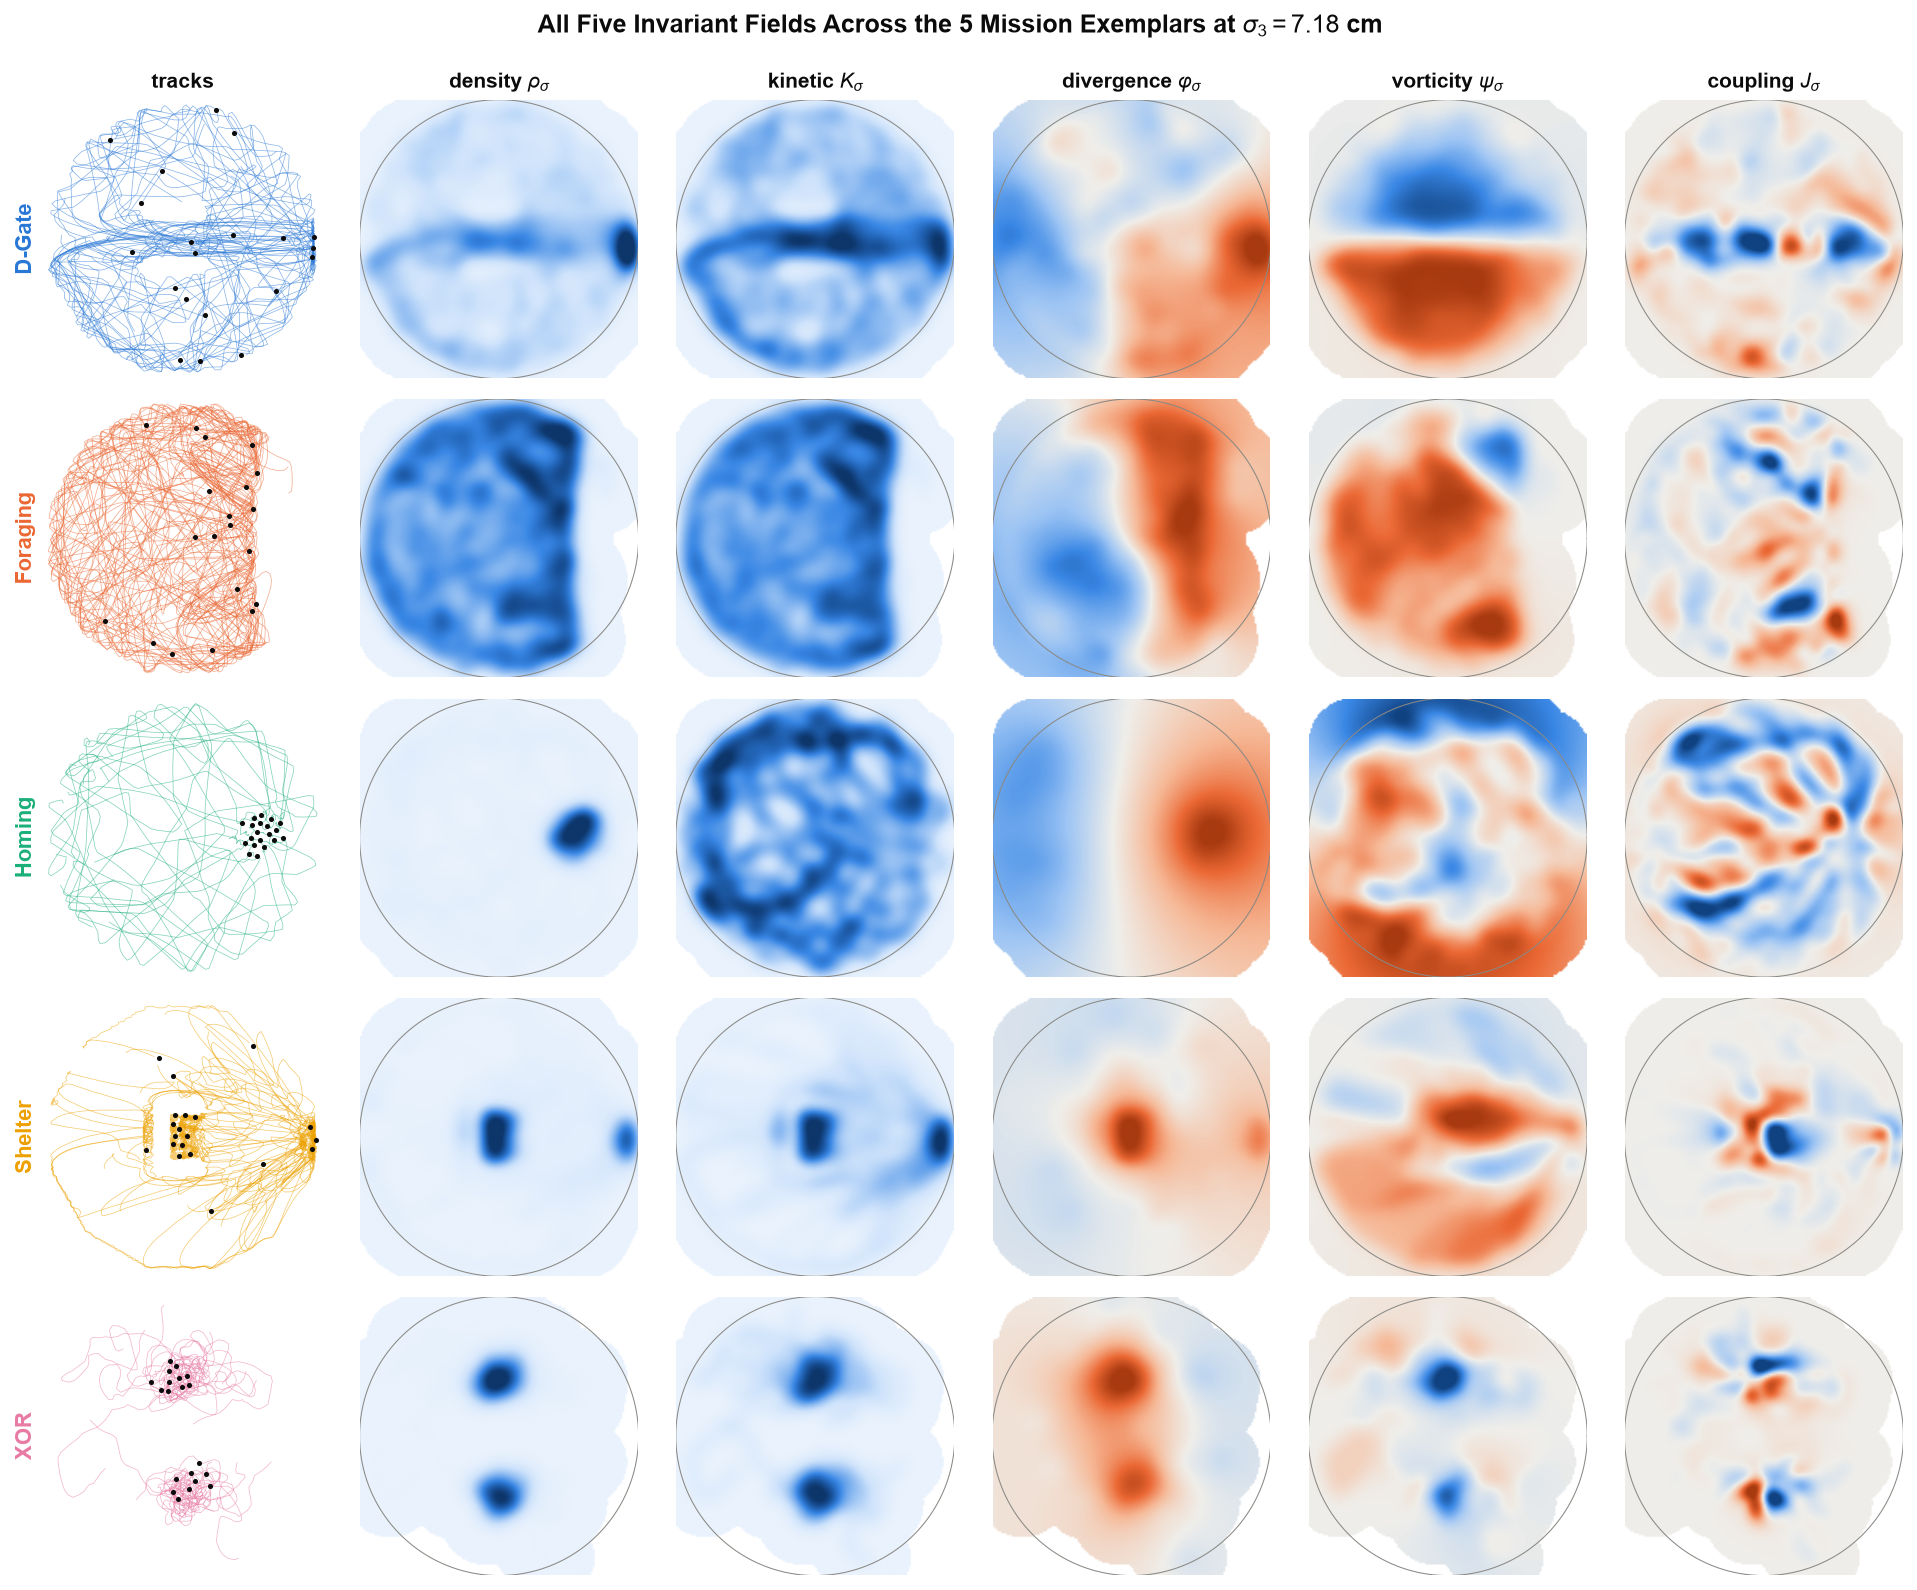

In [7]:
cache = load(PAPER / "display_fields.pkl")
si = 2
ladder = load(RES / "scale_ladder.pkl")["ladder"]
titles = {"rho": r"density $\rho_\sigma$", "K": r"kinetic $K_\sigma$", "phi": r"divergence $\varphi_\sigma$",
          "psi": r"vorticity $\psi_\sigma$", "J": r"coupling $J_\sigma$"}

fig, axes = plt.subplots(5, 6, figsize=(13.0, 10.6))
for r_i, m in enumerate(range(5)):
    e = ex_by_m[m]
    M.draw_tracks(axes[r_i, 0], tracks[e]["pos"], L.MCOL[m], every=6)
    axes[r_i, 0].set_ylabel(L.MSHORT[m], fontsize=10.5, fontweight="bold", color=L.MCOL[m])
    F = cache[("ladder", e, si)]
    for c_i, f in enumerate(L.FIELDS):
        L.show_field(axes[r_i, c_i + 1], F[f], f, arena=True)
        if r_i == 0:
            axes[0, c_i + 1].set_title(titles[f], fontsize=10, fontweight="bold")
axes[0, 0].set_title("tracks", fontsize=10, fontweight="bold")
fig.suptitle(rf"All Five Invariant Fields Across the 5 Mission Exemplars at $\sigma_3 = {100*ladder[si]:.2f}$ cm", fontsize=12, fontweight="bold", y=0.995)
plt.tight_layout(); plt.show()

Backend used: CUDA GPU | Max relative error after 90° rotation:
  rho : 7.31e-07
  K   : 7.08e-07
  phi : 4.89e-07
  psi : 5.27e-07
  J   : 1.47e-06


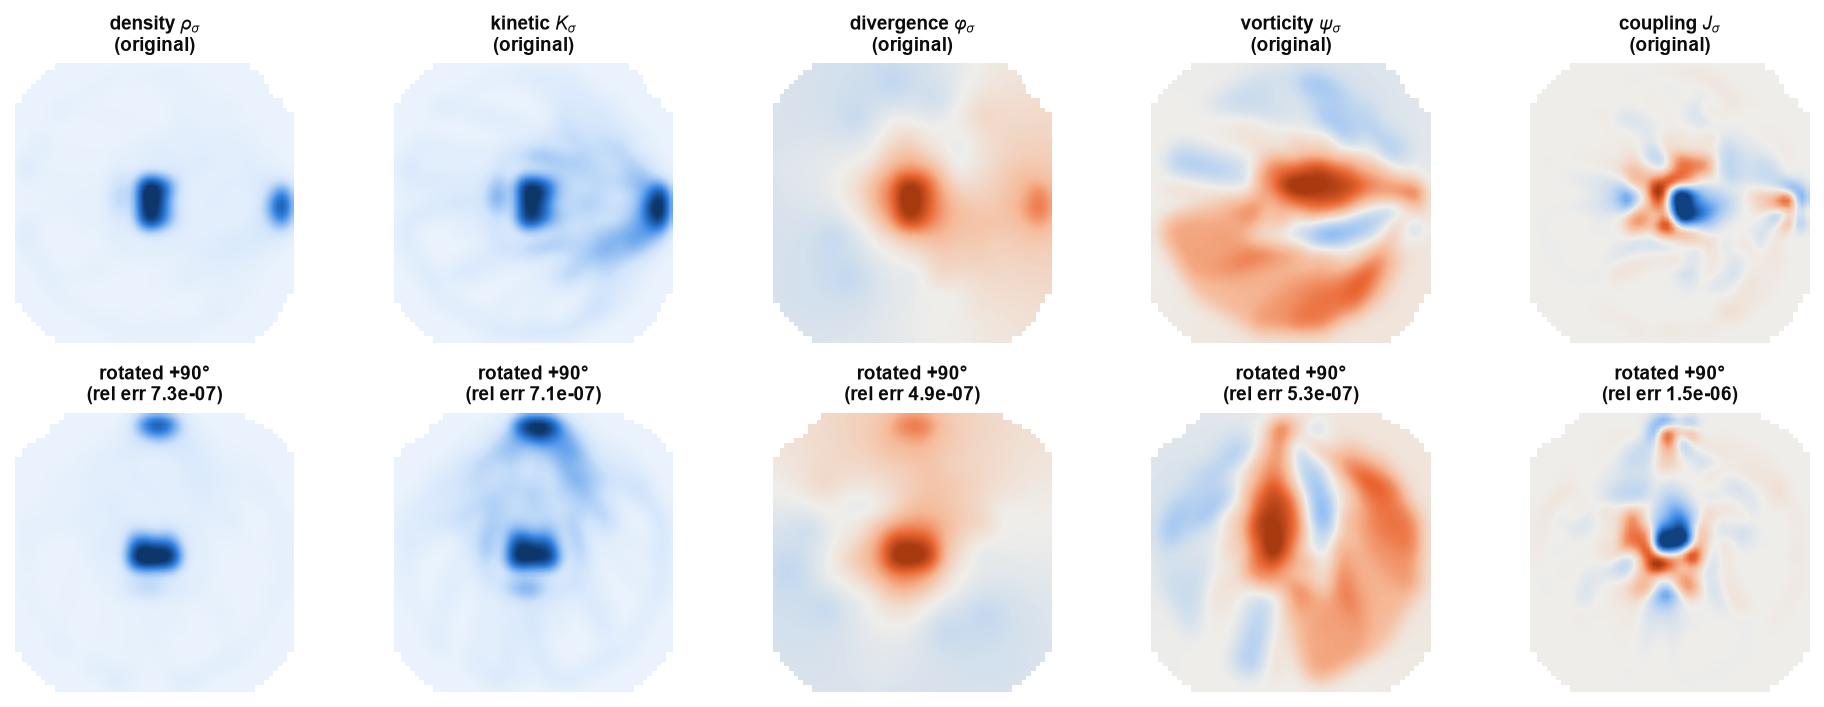

In [8]:
import torch
use_gpu = torch.cuda.is_available()
e_test = ex_by_m[3]  # Shelter exemplar
F60 = L.display_fields(tracks[e_test]["pos"], tracks[e_test]["vel"], float(ladder[si]), n=60, gpu=use_gpu, chunk=60)

c_ar = L.ARENA / 2
R90 = np.array([[0.0, -1.0], [1.0, 0.0]])
pos_rot = (tracks[e_test]["pos"] - c_ar) @ R90.T + c_ar
vel_rot = tracks[e_test]["vel"] @ R90.T
F60_rot = L.display_fields(pos_rot.astype(np.float32), vel_rot.astype(np.float32), float(ladder[si]), n=60, gpu=use_gpu, chunk=60)

print(f"Backend used: {'CUDA GPU' if use_gpu else 'CPU'} | Max relative error after 90° rotation:")
fig, axes = plt.subplots(2, 5, figsize=(12.8, 4.8))
for c_i, f in enumerate(L.FIELDS):
    a = np.rot90(F60[f], k=-1)
    b = F60_rot[f]
    mask = np.isfinite(a) & np.isfinite(b)
    rel = np.abs(a[mask] - b[mask]).max() / max(np.abs(a[mask]).max(), 1e-12)
    print(f"  {f:4s}: {rel:.2e}")
    L.show_field(axes[0, c_i], F60[f], f); axes[0, c_i].set_title(f"{titles[f]}\n(original)", fontsize=9)
    L.show_field(axes[1, c_i], F60_rot[f], f); axes[1, c_i].set_title(f"rotated +90°\n(rel err {rel:.1e})", fontsize=9)
plt.tight_layout(); plt.show()